# 07 — Brain state or artifact?

Rest and the SIMKAP test differ in more than mental load: during the test people move their eyes across the screen, blink at a different
rate and tense forehead and jaw muscles. Eight of the 14 EPOC electrodes are frontal, and notebook 05 found that the classifier leans most
heavily on F8, beside the right eye. This notebook tests how much of the rest-vs-task classification survives when those sources are removed.

All models are L2 logistic regression trained with the same nested, participant-grouped cross-validation as notebook 04
(outer `GroupKFold(8)`, inner `GroupKFold(4)` for C), on **the same 5 554 windows and the same outer folds**. The reference row is the
main model's own out-of-fold predictions. 95 % CIs resample participants (1 000 draws); ΔAUC CIs are paired (same participants in each draw).

| Analysis | What changes |
|---|---|
| a. channel subsets | posterior only (O1, O2, P7, P8); temporal only (T7, T8); all except the four eye-adjacent channels |
| b. band ablations | signal re-filtered and features recomputed without δ (4–45 Hz), without γ (1–30 Hz), or without both (4–30 Hz) |
| c. ocular correction | ICA per recording, eye components removed, all features recomputed |
| d. artifact-only | six artifact markers only: blink count, VEOG and HEOG proxy power, frontal δ power, frontal and temporal 20–45 Hz power |
| e. time split | train on the first half of recordings, test on the second half — across participants and within participants — plus a drift control |

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from scipy import stats
from scipy.signal import butter, sosfiltfilt
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from joblib import Parallel, delayed

from data_loader import CHANNELS, CONDITIONS, FS, load_all
from preprocessing import PreprocessConfig, preprocess
from feature_extraction import BANDS, extract, channel_of
from modeling import model_specs, nested_cv
from evaluation import recording_level
import confounds as cf

warnings.filterwarnings("ignore", category=RuntimeWarning)
OUT = ROOT / "results" / "07_confounds"; OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "results" / "figures" / "07_confounds"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 170, "display.max_columns", 30)
COND_COLOR = {"lo": "#4C72B0", "hi": "#DD8452"}

CFG = PreprocessConfig()
table = pd.read_csv(ROOT / "data" / "features" / "features.csv.gz")
META_COLS = ["subject", "condition", "label", "start_s"]
meta, X = table[META_COLS], table.drop(columns=META_COLS)
y, groups = meta.label.values, meta.subject.values
LR = model_specs()["logreg"]
P04 = pd.read_csv(ROOT / "results" / "04_modeling" / "oof_predictions.csv.gz")
ref = P04[P04.model == "logreg"].reset_index(drop=True)
assert (ref[["subject", "condition", "start_s"]].values == meta[["subject", "condition", "start_s"]].values).all()
ref_score = ref.score.values
recs = load_all()
proc = {k: preprocess(r, CFG) for k, r in recs.items()}
starts = {k: (meta.loc[(meta.subject == k[0]) & (meta.condition == k[1]), "start_s"].values * FS).astype(int) for k in proc}
print("windows:", len(meta), "| reference AUC (notebook 04 logistic regression):", round(roc_auc_score(y, ref_score), 3))

windows: 5554 | reference AUC (notebook 04 logistic regression): 0.881


## Helpers

`run(X)` = nested CV on a feature matrix whose rows are aligned with `meta`. `summarise` adds the participant-bootstrap CI, the paired ΔAUC
versus the reference, recording-level accuracy (window scores averaged per recording, threshold 0.5) and the median per-participant AUC.

In [2]:
def run(Xv, **kw):
    return nested_cv(LR, Xv.reset_index(drop=True), y, groups, outer_splits=8, inner_splits=4, n_jobs=8, **kw)

def per_subject_auc(score, mask=None):
    d = meta.assign(score=score)
    if mask is not None: d = d[mask]
    return d.groupby("subject").apply(lambda g: roc_auc_score(g.label, g.score) if g.label.nunique() == 2 else np.nan, include_groups=False)

rows = []
def summarise(section, name, score, n_feat, mask=None, reference=ref_score, note=""):
    m = np.ones(len(y), bool) if mask is None else mask
    bs = cf.paired_bootstrap(groups[m], y[m], score[m], reference[m])
    rec = recording_level(meta[m].reset_index(drop=True), pd.DataFrame({"score": score[m]}), 0.5)
    row = {"section": section, "analysis": name, "n_features": n_feat, "n_windows": int(m.sum()),
           "auc": bs["auc_a"], "auc_lo": bs["ci_a"][0], "auc_hi": bs["ci_a"][1],
           "ref_auc": bs["auc_b"], "delta_auc": bs["diff"], "delta_lo": bs["ci_diff"][0], "delta_hi": bs["ci_diff"][1],
           "rec_acc": float((rec.pred == rec.label).mean()), "subject_auc_median": float(per_subject_auc(score, m).median()), "note": note}
    rows.append(row)
    print(f"{name:<38} AUC {row['auc']:.3f} [{row['auc_lo']:.3f}, {row['auc_hi']:.3f}]  Δ {row['delta_auc']:+.3f} [{row['delta_lo']:+.3f}, {row['delta_hi']:+.3f}]  rec.acc {row['rec_acc']:.3f}")
    return row

summarise("reference", "All 282 features (notebook 04)", ref_score, X.shape[1])

All 282 features (notebook 04)         AUC 0.881 [0.838, 0.918]  Δ +0.000 [+0.000, +0.000]  rec.acc 0.865


## a. Channel subsets

Regional features that combine channels (frontal θ / parietal α, frontal alpha asymmetry) are dropped whenever one of their channels is excluded.

In [3]:
def cols_for(chs):
    return [c for c in X.columns if channel_of(c) in chs]
EYE = {"AF3", "AF4", "F7", "F8"}
variants_a = {
    "Posterior only (O1, O2, P7, P8)": cols_for({"O1", "O2", "P7", "P8"}),
    "Temporal only (T7, T8)": cols_for({"T7", "T8"}),
    "Without AF3, AF4, F7, F8": [c for c in X.columns if channel_of(c) and channel_of(c) not in EYE] + ["faa_F4F3"],
}
oof_store = {}
for name, cols in variants_a.items():
    o = run(X[cols]); oof_store[name] = o.score.values
    summarise("a. channels", name, o.score.values, len(cols))

Posterior only (O1, O2, P7, P8)        AUC 0.817 [0.771, 0.856]  Δ -0.064 [-0.091, -0.037]  rec.acc 0.854


Temporal only (T7, T8)                 AUC 0.725 [0.669, 0.780]  Δ -0.156 [-0.216, -0.096]  rec.acc 0.740


Without AF3, AF4, F7, F8               AUC 0.824 [0.763, 0.876]  Δ -0.057 [-0.090, -0.024]  rec.acc 0.823


## b. Band ablations (strict)

Dropping the δ or γ *feature columns* is not enough: time-domain features (variance, Hjorth parameters, line length), spectral entropy and every
relative power still integrate over the removed band. So each recording is re-filtered to the reduced range with the same zero-phase Butterworth
design, and all features are recomputed on the same windows. Rejection and bad-channel decisions are kept from the main pipeline so that the
window set is identical.

In [4]:
def features_from(signal_fn, bands, total):
    parts = []
    for k, p in proc.items():
        if len(starts[k]) == 0: continue
        xs = signal_fn(k, p)
        parts.append((k, extract(cf.window_array(xs, ~p.bad_channels, starts[k]), bands, total)))
    # reassemble in the row order of `meta`
    lookup = {k: df for k, df in parts}
    out = []
    for (s, c), g in meta.groupby(["subject", "condition"], sort=False):
        out.append(lookup[(s, c)].set_axis(g.index))
    return pd.concat(out).loc[meta.index]

def refiltered(hp, lp):
    cfg = replace(CFG, hp_hz=hp, lp_hz=lp)
    from preprocessing import filter_recording
    return lambda k, p: filter_recording(recs[k].data, cfg)

band_sets = {
    "Without δ (4–45 Hz)": (4.0, 45.0, {b: v for b, v in BANDS.items() if b != "delta"}),
    "Without γ (1–30 Hz)": (1.0, 30.0, {b: v for b, v in BANDS.items() if b != "gamma"}),
    "Without δ and γ (4–30 Hz)": (4.0, 30.0, {b: v for b, v in BANDS.items() if b not in ("delta", "gamma")}),
}
for name, (hp, lp, bands) in band_sets.items():
    Xb = features_from(refiltered(hp, lp), bands, (hp, lp))
    o = run(Xb); oof_store[name] = o.score.values
    summarise("b. bands", name, o.score.values, Xb.shape[1])

Without δ (4–45 Hz)                    AUC 0.842 [0.794, 0.886]  Δ -0.039 [-0.065, -0.014]  rec.acc 0.854


Without γ (1–30 Hz)                    AUC 0.880 [0.837, 0.917]  Δ -0.000 [-0.010, +0.010]  rec.acc 0.885


Without δ and γ (4–30 Hz)              AUC 0.854 [0.808, 0.898]  Δ -0.027 [-0.047, -0.004]  rec.acc 0.865


## c. Ocular correction with ICA

For each recording, FastICA (as many components as good channels) is fitted on the band-passed signal, excluding saturated samples. Two EOG
proxies are built from the EEG itself because STEW has no EOG channel: **VEOG** = mean(AF3, AF4) and **HEOG** = F7 − F8, both low-passed at 4 Hz.
For each proxy the single best-matching component is removed if its low-passed time course correlates with the proxy at |r| ≥ 0.7. This removes at
most two components per recording. The threshold was fixed before looking at classification results, from the distribution of correlations:
the best match is usually 0.7–0.99, the runner-up often 0.5–0.7 and ambiguous.

Caveat built into the method: the proxies are frontal EEG, so a removed component can also carry frontal brain activity (including frontal θ).

In [5]:
def _ica(k):
    p = proc[k]
    ok = ~p.sample_mask[:, ~p.bad_channels].any(axis=1)
    xc, info = cf.ocular_ica(p.x.astype(float), ~p.bad_channels, ok)
    return k, xc, info
res = Parallel(n_jobs=8)(delayed(_ica)(k) for k in proc)
clean = {k: xc for k, xc, _ in res}
ica_info = pd.DataFrame([{"subject": k[0], "condition": k[1], "n_removed": len(i["removed"]),
                          "r_veog": i["r"].get("veog", np.nan), "r_heog": i["r"].get("heog", np.nan)} for k, _, i in res])
print("components removed per recording:"); display(ica_info.groupby("condition").n_removed.value_counts().unstack(fill_value=0).rename(index=CONDITIONS))
print("mean components removed:", ica_info.groupby("condition").n_removed.mean().rename(index=CONDITIONS).round(2).to_dict())

# effect on frontal δ power and on O1 (should change little)
lp4 = butter(4, [1, 4], btype="bandpass", fs=FS, output="sos")
chg = []
for k, p in proc.items():
    for ch in ("AF3", "F8", "O1"):
        i = CHANNELS.index(ch)
        if p.bad_channels[i]: continue
        before = np.var(sosfiltfilt(lp4, p.x[:, i].astype(float))); after = np.var(sosfiltfilt(lp4, clean[k][:, i]))
        chg.append({"condition": k[1], "channel": ch, "delta_power_change_db": 10 * np.log10(after / before)})
chg = pd.DataFrame(chg)
display(chg.groupby(["channel", "condition"]).delta_power_change_db.median().unstack().rename(columns=CONDITIONS).round(2))

Xi = features_from(lambda k, p: clean[k], BANDS, (1.0, 45.0))
o = run(Xi); oof_store["ICA"] = o.score.values
summarise("c. ocular ICA", "ICA, eye components removed", o.score.values, Xi.shape[1])
lp30 = butter(4, 30, btype="low", fs=FS, output="sos")
Xi30 = features_from(lambda k, p: sosfiltfilt(lp30, clean[k], axis=0), {b: v for b, v in BANDS.items() if b != "gamma"}, (1.0, 30.0))
o = run(Xi30); oof_store["ICA no gamma"] = o.score.values
summarise("c. ocular ICA", "ICA + without γ (1–30 Hz)", o.score.values, Xi30.shape[1])

components removed per recording:


n_removed,0,1,2
condition,,,
test,1,18,29
rest,2,17,29


mean components removed: {'test': 1.58, 'rest': 1.56}


condition,test,rest
channel,,
AF3,-1.22,-5.55
F8,-3.44,-3.55
O1,-0.19,-0.12


ICA, eye components removed            AUC 0.827 [0.785, 0.870]  Δ -0.054 [-0.096, -0.010]  rec.acc 0.823


ICA + without γ (1–30 Hz)              AUC 0.808 [0.754, 0.859]  Δ -0.073 [-0.119, -0.027]  rec.acc 0.760


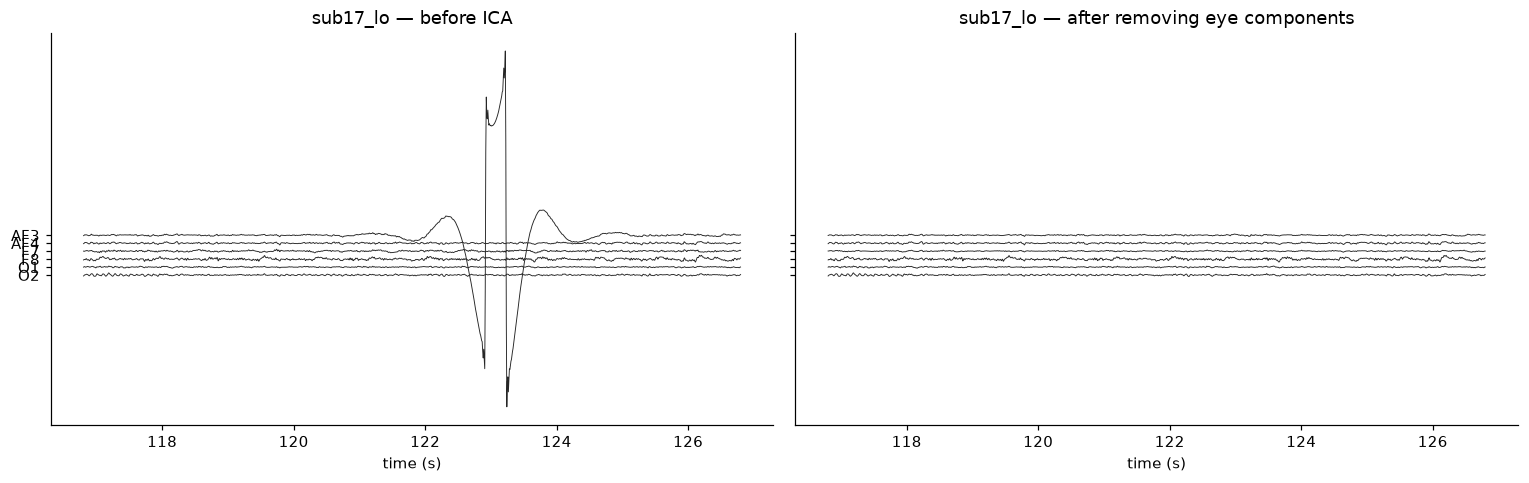

In [6]:
k = ica_info.sort_values("r_veog", ascending=False).iloc[0]; k = (int(k.subject), k.condition)
p = proc[k]; t = np.arange(len(p.x)) / FS
blinks = cf.blink_peaks(cf.eog_proxies(p.x.astype(float), ~p.bad_channels)["veog"]) / FS
t0 = blinks[len(blinks) // 2] - 5 if len(blinks) else 60; sl = (t >= t0) & (t < t0 + 10)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (x, title) in zip(axes, [(p.x.astype(float), "before ICA"), (clean[k], "after removing eye components")]):
    for j, ch in enumerate(["AF3", "AF4", "F7", "F8", "O1", "O2"]):
        ax.plot(t[sl], x[sl, CHANNELS.index(ch)] - j * 120, lw=0.6, color="0.15")
    ax.set_yticks([-j * 120 for j in range(6)], ["AF3", "AF4", "F7", "F8", "O1", "O2"]); ax.set_title(f"sub{k[0]:02d}_{k[1]} — {title}"); ax.set_xlabel("time (s)"); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "ica_example.png", bbox_inches="tight"); plt.show()

## d. Artifact-only model

Six markers per window, chosen to describe eye and muscle activity rather than brain rhythms:

| Feature | Definition |
|---|---|
| `blink_count` | peaks of \|VEOG − median\| above 5 robust SDs of that recording's VEOG, ≥ 0.3 s apart, inside the window |
| `veog_logpow`, `heog_logpow` | log power of the 1–4 Hz VEOG / HEOG proxies in the window |
| `frontal_delta_logpow` | log mean 1–4 Hz power at AF3, AF4, F7, F8 |
| `frontal_hf_logpow` | log mean 20–45 Hz power at AF3, AF4, F7, F8 (forehead muscle) |
| `temporal_hf_logpow` | log mean 20–45 Hz power at T7, T8 (jaw / temporalis muscle) |

The blink threshold is relative to each recording (label-blind), so the count reflects blink *events*, not absolute amplitude.

In [7]:
parts = {}
for k, p in proc.items():
    if len(starts[k]): parts[k] = cf.artifact_features(p.x.astype(float), ~p.bad_channels, starts[k])
Xa = pd.concat([parts[(s, c)].set_axis(g.index) for (s, c), g in meta.groupby(["subject", "condition"], sort=False)]).loc[meta.index]
print("NaN share per artifact feature:", Xa.isna().mean().round(3).to_dict())

uni = pd.DataFrame({c: {"window_auc_univariate": roc_auc_score(y[Xa[c].notna()], Xa[c].dropna())} for c in Xa}).T
display(uni.round(3))
blink_rate = (meta.assign(b=Xa.blink_count.values).groupby(["subject", "condition"]).b.mean() * 15).unstack()  # per minute
w = stats.wilcoxon(blink_rate["hi"], blink_rate["lo"])
print(f"blinks per minute (clean windows): rest median {blink_rate['lo'].median():.1f}, test median {blink_rate['hi'].median():.1f}; "
      f"higher during test in {(blink_rate['hi'] > blink_rate['lo']).sum()}/48 participants; Wilcoxon p = {w.pvalue:.2g}")

o = run(Xa); oof_store["artifact only"] = o.score.values
summarise("d. artifact-only", "Artifact markers only (6)", o.score.values, Xa.shape[1])
art98 = [c for c in X.columns if (c.split("_", 1)[1] if channel_of(c) else c) in ("kurt", "skew", "log_ll", "abs_delta", "rel_delta", "abs_gamma", "rel_gamma")]
o = run(X[art98]); oof_store["artifact broad"] = o.score.values
summarise("d. artifact-only", "Broad artifact proxies (δ, γ, shape; 98)", o.score.values, len(art98))
Xboth = pd.concat([Xa, X], axis=1)

NaN share per artifact feature: {'blink_count': 0.0, 'veog_logpow': 0.0, 'heog_logpow': 0.01, 'frontal_hf_logpow': 0.0, 'temporal_hf_logpow': 0.0, 'frontal_delta_logpow': 0.0}


,window_auc_univariate
blink_count,0.501
veog_logpow,0.473
heog_logpow,0.743
frontal_hf_logpow,0.653
temporal_hf_logpow,0.525
frontal_delta_logpow,0.552


blinks per minute (clean windows): rest median 3.8, test median 4.4; higher during test in 28/48 participants; Wilcoxon p = 0.51


Artifact markers only (6)              AUC 0.765 [0.715, 0.821]  Δ -0.116 [-0.172, -0.056]  rec.acc 0.740


Broad artifact proxies (δ, γ, shape; 98) AUC 0.787 [0.730, 0.836]  Δ -0.094 [-0.125, -0.069]  rec.acc 0.760


## e. Time split: how much is session or drift identification?

Halves: first = windows ending by 75 s; second = windows starting at ≥ 79 s (4 s gap, no shared samples).

* **e1 (across participants).** Outer folds as before, but training uses only first-half windows of the training participants; testing uses
  second-half windows of held-out participants. Reference: the main model scored on the same second-half windows.
* **e2 (within participant).** For each participant separately: train on their own first halves (both conditions), test on their second halves.
  No other person is involved, so here the model can exploit anything that differs between the two recordings — electrode contact, headset position, drift.
* **e3 (drift control, within recording).** Inside *one* recording (one condition), label windows by time: quarter 1 vs quarter 3 for training,
  quarter 2 vs quarter 4 for testing. Mental state is nominally constant, so any separability here is drift or session change. If e3 is high, a high
  e2 cannot be credited to mental state.

In [8]:
first = (meta.start_s + 4 <= 75).values
second = (meta.start_s >= 79).values
o = run(X, train_mask=first, test_mask=second)
e1 = np.full(len(y), np.nan); e1[o.index] = o.score.values
summarise("e. time split", "e1 Train first half → test second half (across participants)", e1, X.shape[1], mask=second,
          note="reference = main model on the same second-half windows")

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
C = pd.Series([eval(b)["clf__C"] for b in json.load(open(ROOT / "results/04_modeling/summary.json"))["best_params_per_fold"]["logreg"]]).mode()[0]
WS = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(), LogisticRegression(C=C, max_iter=5000))
e2 = np.full(len(y), np.nan); e2_sub = {}
for s in np.unique(groups):
    m = groups == s; tr = np.flatnonzero(m & first); te = np.flatnonzero(m & second)
    if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2: continue
    e2[te] = clone(WS).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
    e2_sub[s] = roc_auc_score(y[te], e2[te])
ok2 = second & ~np.isnan(e2)
summarise("e. time split", "e2 Same, within each participant", np.nan_to_num(e2), X.shape[1], mask=ok2,
          note=f"{len(e2_sub)} participants; per-participant models, C={C}")

centre = meta.start_s.values + 2
q = np.select([(meta.start_s + 4 <= 37.5), (meta.start_s >= 37.5) & (meta.start_s + 4 <= 75),
               (meta.start_s >= 75) & (meta.start_s + 4 <= 112.5), (meta.start_s >= 112.5)], [1, 2, 3, 4], 0)
e3_rec = []
for (s, c), g in meta.groupby(["subject", "condition"]):
    i = g.index.values; qi = q[i]
    tr = i[np.isin(qi, [1, 3])]; te = i[np.isin(qi, [2, 4])]
    ytr = (q[tr] == 3).astype(int); yte = (q[te] == 4).astype(int)
    if min(np.bincount(ytr, minlength=2)) < 3 or min(np.bincount(yte, minlength=2)) < 3: continue
    sc = clone(WS).fit(X.loc[tr], ytr).predict_proba(X.loc[te])[:, 1]
    e3_rec.append({"subject": s, "condition": c, "auc": roc_auc_score(yte, sc), "n_test": len(te)})
e3_rec = pd.DataFrame(e3_rec)
print(f"e3 drift control: {len(e3_rec)} recordings; median AUC (Q2 vs Q4) {e3_rec.auc.median():.3f}; "
      f"recordings with AUC ≥ 0.8: {(e3_rec.auc >= 0.8).sum()}/{len(e3_rec)}; by condition: {e3_rec.groupby('condition').auc.median().rename(index=CONDITIONS).round(3).to_dict()}")
bs = np.random.default_rng(0)
boot = [np.median(bs.choice(e3_rec.auc.values, len(e3_rec))) for _ in range(1000)]
e3_ci = np.percentile(boot, [2.5, 97.5])
print(f"e2 within-participant: median per-participant AUC {np.median(list(e2_sub.values())):.3f} ({len(e2_sub)} participants)")

e1 Train first half → test second half (across participants) AUC 0.872 [0.820, 0.916]  Δ -0.002 [-0.014, +0.010]  rec.acc 0.874


e2 Same, within each participant       AUC 0.985 [0.973, 0.994]  Δ +0.112 [+0.070, +0.168]  rec.acc 0.979


e3 drift control: 86 recordings; median AUC (Q2 vs Q4) 0.629; recordings with AUC ≥ 0.8: 20/86; by condition: {'test': 0.567, 'rest': 0.698}
e2 within-participant: median per-participant AUC 1.000 (47 participants)


## Summary table

,section,analysis,n_features,auc,auc_lo,auc_hi,delta_auc,delta_lo,delta_hi,rec_acc,subject_auc_median
0,reference,All 282 features (notebook 04),282,0.881,0.838,0.918,0.000,0.000,0.000,0.865,0.952
1,a. channels,"Posterior only (O1, O2, P7, P8)",80,0.817,0.771,0.856,-0.064,-0.091,-0.037,0.854,0.880
2,a. channels,"Temporal only (T7, T8)",40,0.725,0.669,0.780,-0.156,-0.216,-0.096,0.740,0.808
3,a. channels,"Without AF3, AF4, F7, F8",201,0.824,0.763,0.876,-0.057,-0.090,-0.024,0.823,0.938
4,b. bands,Without δ (4–45 Hz),254,0.842,0.794,0.886,-0.039,-0.065,-0.014,0.854,0.946
5,b. bands,Without γ (1–30 Hz),254,0.880,0.837,0.917,-0.000,-0.010,0.010,0.885,0.944
6,b. bands,Without δ and γ (4–30 Hz),226,0.854,0.808,0.898,-0.027,-0.047,-0.004,0.865,0.938
7,c. ocular ICA,"ICA, eye components removed",282,0.827,0.785,0.870,-0.054,-0.096,-0.010,0.823,0.916
8,c. ocular ICA,ICA + without γ (1–30 Hz),254,0.808,0.754,0.859,-0.073,-0.119,-0.027,0.760,0.921
9,d. artifact-only,Artifact markers only (6),6,0.765,0.715,0.821,-0.116,-0.172,-0.056,0.740,0.849


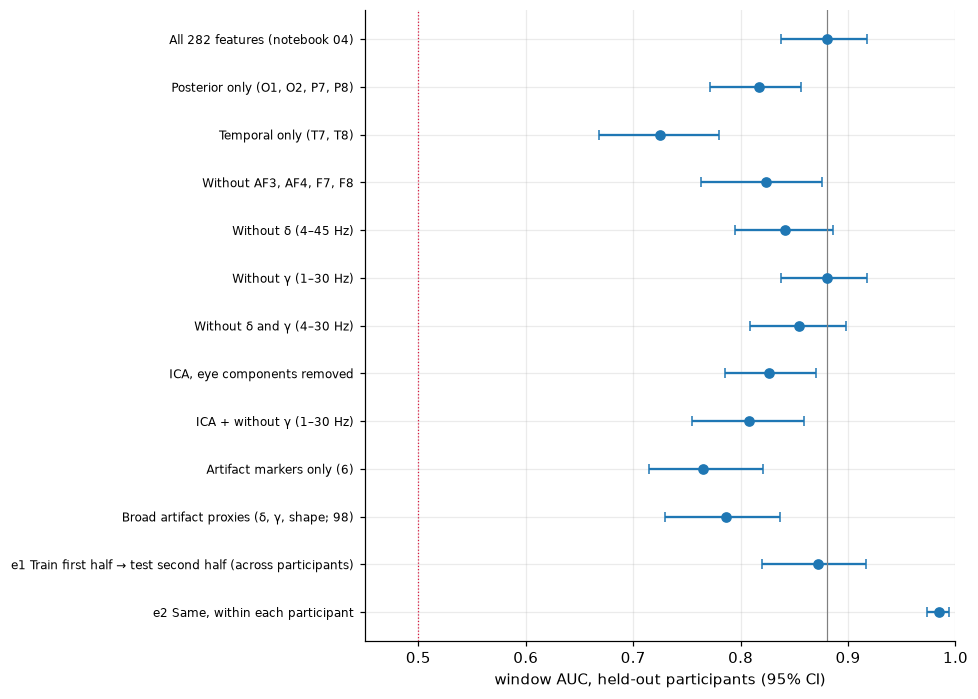

In [9]:
tab = pd.DataFrame(rows)
tab.loc[len(tab)] = {"section": "e. time split", "analysis": "e3 Drift control: early vs late in one recording", "n_features": X.shape[1],
                     "n_windows": int(e3_rec.n_test.sum()), "auc": np.nan, "auc_lo": np.nan, "auc_hi": np.nan, "ref_auc": np.nan,
                     "delta_auc": np.nan, "delta_lo": np.nan, "delta_hi": np.nan, "rec_acc": np.nan,
                     "subject_auc_median": float(e3_rec.auc.median()),
                     "note": f"median per-recording AUC over {len(e3_rec)} recordings, 95% CI of the median {e3_ci[0]:.3f}–{e3_ci[1]:.3f}"}
display(tab[["section", "analysis", "n_features", "auc", "auc_lo", "auc_hi", "delta_auc", "delta_lo", "delta_hi", "rec_acc", "subject_auc_median"]].round(3))

plot = tab.dropna(subset=["auc"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(plot) + 1))
yy = np.arange(len(plot))
ax.errorbar(plot.auc, yy, xerr=[plot.auc - plot.auc_lo, plot.auc_hi - plot.auc], fmt="o", color="#1f77b4", capsize=3)
ax.axvline(plot.loc[plot.section == "reference", "auc"].iloc[0], color="0.5", lw=0.8); ax.axvline(0.5, color="crimson", lw=0.8, ls=":")
ax.set_yticks(yy, plot.analysis, fontsize=8); ax.set_xlabel("window AUC, held-out participants (95% CI)"); ax.set_xlim(0.45, 1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "confound_auc.png", bbox_inches="tight"); plt.show()

In [10]:
tab.to_csv(OUT / "confound_table.csv", index=False)
ica_info.to_csv(OUT / "ica_components.csv", index=False)
e3_rec.to_csv(OUT / "drift_control.csv", index=False)
summary = {
    "table": tab.replace({np.nan: None}).to_dict(orient="records"),
    "ica": {"threshold_abs_r": cf.ICA_R_THRESHOLD, "eog_lowpass_hz": cf.EOG_LOWPASS_HZ, "seed": cf.ICA_SEED,
            "mean_removed": ica_info.groupby("condition").n_removed.mean().round(3).to_dict(),
            "recordings_with_removal": ica_info.assign(any_=ica_info.n_removed > 0).groupby("condition").any_.sum().to_dict(),
            "frontal_delta_change_db_median": chg.groupby(["channel", "condition"]).delta_power_change_db.median().unstack().round(2).to_dict(orient="index")},
    "blinks_per_minute": {"rest_median": float(blink_rate["lo"].median()), "test_median": float(blink_rate["hi"].median()),
                          "n_higher_in_test": int((blink_rate["hi"] > blink_rate["lo"]).sum()), "wilcoxon_p": float(w.pvalue)},
    "artifact_univariate_auc": uni.window_auc_univariate.round(4).to_dict(),
    "within_participant_e2": {"n": len(e2_sub), "median_auc": float(np.median(list(e2_sub.values())))},
    "drift_control_e3": {"n_recordings": len(e3_rec), "median_auc": float(e3_rec.auc.median()), "ci_median": [float(e3_ci[0]), float(e3_ci[1])],
                         "n_ge_0_8": int((e3_rec.auc >= 0.8).sum()), "by_condition": e3_rec.groupby("condition").auc.median().round(4).to_dict()},
    "cv": "nested GroupKFold(8)/GroupKFold(4) by participant, logistic regression; same windows and outer folds as notebook 04",
}
with open(OUT / "summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved:", *sorted(p.name for p in OUT.iterdir()))

saved: confound_table.csv drift_control.csv ica_components.csv summary.json


## Findings

Reference: logistic regression on all 282 features, window AUC 0.881 (95% CI 0.838–0.918).

**Eye activity accounts for part of the accuracy.** Posterior channels only: 0.817 (Δ −0.064, CI −0.091 to −0.037). Without AF3, AF4, F7, F8: 0.824 (Δ −0.057).
ICA with eye components removed: 0.827 (Δ −0.054, CI −0.096 to −0.010); ICA plus removing γ: 0.808 (Δ −0.073). Each of these is reliably lower than the
reference and reliably above chance.

**Muscle (γ) is not what the model uses; low frequencies help a little.** Re-filtering to 1–30 Hz leaves AUC unchanged (0.880, Δ −0.000, CI −0.010 to +0.010).
Re-filtering to 4–45 Hz costs 0.039 (CI −0.065 to −0.014).

**Artifact markers alone get much of the way.** Six markers reach 0.765 (CI 0.715–0.821). The horizontal-eye-movement proxy F7 − F8 is the strongest single one
(univariate AUC 0.743), consistent with scanning the screen during SIMKAP. Blink rate does not differ (median 3.8 vs 4.4 per minute in clean windows, p = 0.51).
ICA removed a similar number of components in both conditions (1.56 rest, 1.58 test), and barely changed O1 (−0.12 dB at 1–4 Hz).

**Drift does not drive the across-person result.** Training on first halves and testing on second halves of held-out participants: 0.872 vs 0.874 for the
main model on the same windows (Δ −0.002, CI −0.014 to +0.010).

**Within-person results are inflated by recording identity.** Within each participant, first half → second half: 0.985. Inside a single recording, where the
task is constant, early vs. late windows are also partly separable: median AUC 0.629 (CI of the median 0.582–0.679), ≥ 0.8 in 20 of 86 recordings.

**Overall.** The claim survives in a narrower form. Rest vs. SIMKAP is classified in unseen participants at about 0.81–0.83 AUC once eye-related signal is
removed, against 0.88 without correction, and an artifact-only model reaches 0.77. Because the EOG proxies are themselves frontal EEG and STEW has no EOG
channel, the residual cannot be shown to be purely neural.
